# 03. Rastreamento e diagnóstico

Antes do tratamento vem o diagnóstico, e antes do diagnóstico, na maioria dos casos, vem a mamografia. Este caderno acompanha esse caminho no SUS. Ele usa o Sistema de Informação do Câncer (SISCAN), onde os serviços públicos registram cada mamografia e cada laudo de biópsia de mama.

O caminho típico é o seguinte. A mulher faz uma mamografia, seja de rastreamento (sem sintomas, como exame periódico) ou diagnóstica (porque já há um sinal, como um nódulo). O laudo classifica o resultado na escala BI-RADS, de 0 a 6. As categorias 1 e 2 são normais ou benignas; a 3 pede acompanhamento; as categorias 4 e 5 indicam achado suspeito e levam à biópsia; a 0 significa que o exame foi inconclusivo e precisa de complemento. A biópsia é analisada pelo patologista, e o laudo de histopatologia confirma ou não o câncer.

O Ministério da Saúde recomenda a mamografia de rastreamento a cada dois anos para mulheres de 50 a 69 anos. Usamos as mamografias de 2019, último ano antes da pandemia, e de 2024, último ano completo.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from mama import codigos as c, graficos as g
from mama.analises import base, rastreamento as ras

pd.set_option("display.max_columns", 20)
mamo = ras.mamografias()
hp = ras.histopatologia()
FONTE_MAMO = "DATASUS, SISCAN, mamografias em mulheres registradas no SUS (2019 e 2024)."
FONTE_HISTO = "DATASUS, SISCAN, laudos de histopatologia de mama com carcinoma invasivo (2014–2024)."
mamo.groupby(["ano", "indicacao"], observed=True).size().unstack()

indicacao,Diagnóstica,Rastreamento
ano,,
2019,77582,2986036
2024,71266,3538688


Em 2024, o SISCAN registrou 3,6 milhões de mamografias em mulheres, 18% a mais do que em 2019. Quase todas (98%) são de rastreamento; as mamografias diagnósticas, feitas porque já havia um sinal, são só 2%.

## Para quem são feitas as mamografias de rastreamento

A recomendação é concentrar o rastreamento entre 50 e 69 anos, a faixa em que o benefício supera os riscos (como falsos positivos e biópsias desnecessárias). O gráfico mostra a idade das mulheres que fizeram mamografia de rastreamento em 2024.

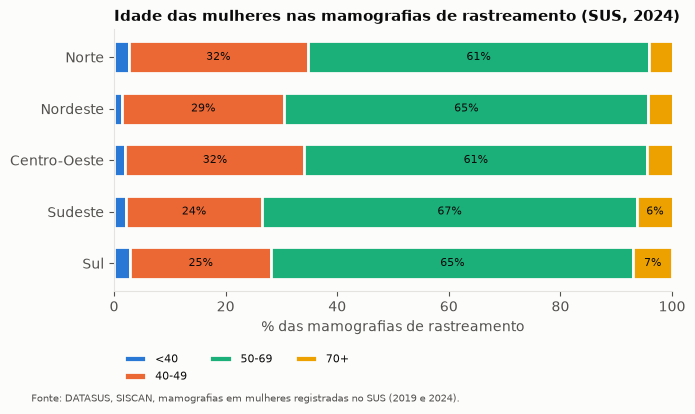

faixa,<40,40-49,50-69,70+
regiao_res,,,,
Norte,2.6,32.1,61.2,4.2
Nordeste,1.4,29.1,65.2,4.4
Centro-Oeste,2.0,32.1,61.4,4.6
Sudeste,2.1,24.4,67.2,6.4
Sul,2.8,25.4,64.8,7.0


In [2]:
rastr = mamo[(mamo.indicacao == "Rastreamento") & (mamo.ano == mamo.ano.max())]
idade = base.distribuicao(rastr.assign(faixa=rastr.faixa_etaria.astype("string")), "faixa", "regiao_res",
                          ordem=c.FAIXAS_ROTULOS)
base.salvar_tabela(idade, "03_idade_mamografias_rastreamento", index=True)
cores_idade = dict(zip(c.FAIXAS_ROTULOS, g.CATEGORICAS[:4]))
fig, ax = g.empilhadas_100(idade, "Idade das mulheres nas mamografias de rastreamento (SUS, 2024)",
                           "% das mamografias de rastreamento", cores=cores_idade)
g.salvar(fig, "03_idade_rastreamento", FONTE_MAMO)
plt.show()
idade

Dois terços das mamografias de rastreamento (65%) são feitas na faixa recomendada, de 50 a 69 anos. Outros 27% são feitos em mulheres de 40 a 49 anos, faixa em que o Ministério da Saúde não recomenda o rastreamento de rotina, mas algumas sociedades médicas sim. No Norte e no Centro-Oeste, essa fatia chega a 32%, contra 24% no Sudeste. É coerente com o caderno 02: nessas regiões as pacientes são mais jovens, e os serviços parecem responder a isso examinando mais cedo.

## Quantas mulheres da faixa-alvo são examinadas

Uma forma simples de medir o alcance do rastreamento é comparar o número de mamografias de rastreamento em mulheres de 50 a 69 anos com a metade da população feminina dessa idade. Usamos a metade porque a recomendação é um exame a cada dois anos: se todas as mulheres seguissem a recomendação, metade delas faria o exame em cada ano. O resultado é expresso como percentual dessa meta.

Dois cuidados são necessários. O primeiro é que essa conta é uma razão de exames, e não uma cobertura exata, porque uma mesma mulher pode fazer mais de um exame no ano. O segundo, mais importante, é que nem toda mamografia do SUS é registrada no SISCAN, e as mamografias feitas por planos de saúde não entram. Por isso, os valores abaixo subestimam o rastreamento real e devem ser usados para comparar regiões e anos entre si, e não como cobertura absoluta.

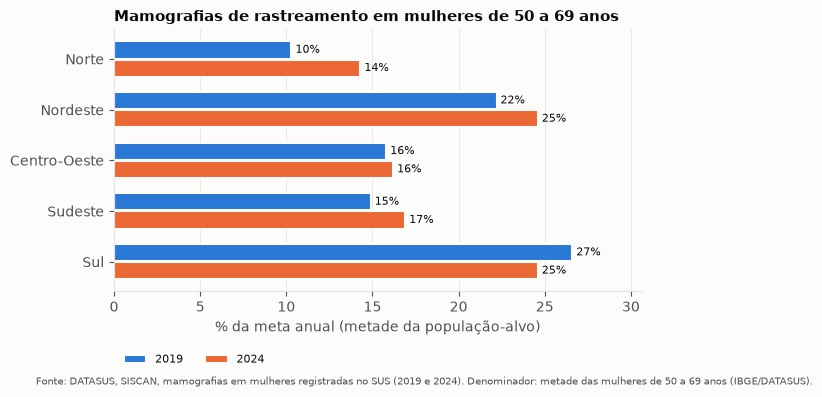

ano,2019,2024
regiao_res,,
Norte,10.3,14.3
Nordeste,22.2,24.6
Centro-Oeste,15.8,16.2
Sudeste,14.9,16.9
Sul,26.6,24.6


In [3]:
cob = ras.cobertura_rastreamento(mamo)
base.salvar_tabela(cob, "03_razao_rastreamento_regiao")
tab = cob.pivot(index="regiao_res", columns="ano", values="razao_pct_da_meta")
fig, ax = plt.subplots(figsize=(6.8, 3.4))
anos = sorted(cob.ano.unique())
pos = range(len(c.REGIOES))
for k, (ano, cor) in enumerate(zip(anos, [g.CATEGORICAS[0], g.CATEGORICAS[1]])):
    v = tab[ano].reindex(c.REGIOES).to_numpy()
    y = [p + (0.18 if k == 0 else -0.18) for p in pos][::-1]
    ax.barh(y, v, height=0.34, color=cor, label=str(ano), edgecolor=g.SUPERFICIE, linewidth=1.5)
    for yy, vv in zip(y, v):
        ax.text(vv, yy, f" {vv:.0f}%", va="center", fontsize=8)
ax.set_yticks(list(pos)[::-1], c.REGIOES)
ax.set(title="Mamografias de rastreamento em mulheres de 50 a 69 anos", xlabel="% da meta anual (metade da população-alvo)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.2), ncol=2, fontsize=8)
ax.set_xlim(0, tab.max().max() * 1.15)
ax.grid(axis="y", visible=False)
g.salvar(fig, "03_razao_rastreamento", FONTE_MAMO + " Denominador: metade das mulheres de 50 a 69 anos (IBGE/DATASUS).")
plt.show()
tab

Os valores são baixos em todas as regiões, entre 14% e 25% da meta em 2024. Parte disso é real e parte é sub-registro: muitos serviços ainda não lançam as mamografias no SISCAN, e o sistema não inclui as mamografias feitas por planos de saúde. Por isso, o mais útil é a comparação. O Norte tem a menor razão do país, embora tenha crescido de 10% para 14% entre 2019 e 2024. Nordeste e Sul estão no topo, em torno de 25%. Sudeste e Centro-Oeste ficam em torno de 16%, valores que provavelmente refletem um sub-registro maior em grandes redes municipais e uma participação maior dos planos de saúde.

## O resultado das mamografias

O gráfico mostra a distribuição das categorias BI-RADS em 2024, e a tabela traz o percentual de exames suspeitos (BI-RADS 4 ou 5) por região.

In [4]:
ultimo = mamo[mamo.ano == mamo.ano.max()]
birads = ultimo.birads.astype("string").value_counts(normalize=True).mul(100).round(2).reindex([str(i) for i in range(7)])
base.salvar_tabela(birads.rename("pct").to_frame(), "03_birads_brasil", index=True)
display(birads.rename("% das mamografias (2024)").to_frame())
susp = ras.birads_suspeito(ultimo, ["regiao_res"])
susp_ind = ras.birads_suspeito(ultimo, ["indicacao"])
base.salvar_tabela(susp, "03_birads_suspeito_regiao")
display(susp_ind)
susp

,% das mamografias (2024)
birads,
0,12.01
1,29.06
2,55.82
3,1.91
4,0.92
5,0.16
6,0.11


,indicacao,n,eventos,pct,ic_inf,ic_sup
0,Diagnóstica,71266,4326,6.1,5.9,6.2
1,Rastreamento,3538688,34919,1.0,1.0,1.0


,regiao_res,n,eventos,pct,ic_inf,ic_sup
0,Centro-Oeste,234242,2929,1.3,1.2,1.3
1,Nordeste,1111320,10349,0.9,0.9,0.9
2,Norte,175426,1966,1.1,1.1,1.2
3,Sudeste,1371197,16325,1.2,1.2,1.2
4,Sul,717769,7676,1.1,1.0,1.1


A maioria das mamografias é normal ou benigna: 56% são BI-RADS 2 e 29% BI-RADS 1. Um em cada oito exames (12%) é BI-RADS 0, inconclusivo, e obriga a mulher a voltar para um exame complementar, geralmente uma ultrassonografia; é uma etapa a mais em que a paciente pode se perder no caminho. Cerca de 1% das mamografias de rastreamento é suspeito (BI-RADS 4 ou 5), o que em 2024 representou cerca de 39 mil mulheres encaminhadas para biópsia. Nas mamografias diagnósticas, o percentual suspeito sobe para 6%, como esperado. As regiões têm percentuais parecidos, em torno de 1%.

## Quanto tempo leva para sair o resultado

O SISCAN registra o intervalo entre a realização da mamografia e a liberação do laudo, em faixas.

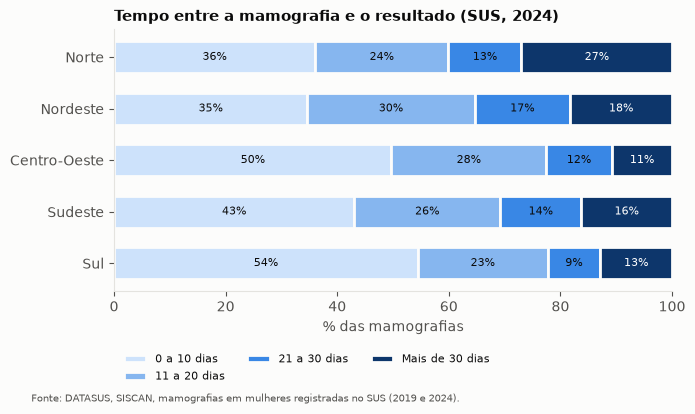

ano,% com resultado após 30 dias em 2019,% com resultado após 30 dias em 2024
regiao_res,,
Norte,30.2,27.0
Nordeste,22.9,18.3
Centro-Oeste,20.9,10.8
Sudeste,15.8,16.3
Sul,11.4,12.9


In [5]:
ordem_int = ["0 a 10 dias", "11 a 20 dias", "21 a 30 dias", "Mais de 30 dias"]
interv = base.distribuicao(ultimo.assign(i=ultimo.intervalo_resultado.astype("string")), "i", "regiao_res", ordem=ordem_int)
base.salvar_tabela(interv, "03_intervalo_resultado_mamografia_regiao", index=True)
fig, ax = g.empilhadas_100(interv, "Tempo entre a mamografia e o resultado (SUS, 2024)", "% das mamografias",
                           cores=dict(zip(ordem_int, ["#cde2fb", "#86b6ef", "#3987e5", "#0d366b"])))
g.salvar(fig, "03_intervalo_resultado_mamografia", FONTE_MAMO)
plt.show()
mais30 = pd.crosstab(mamo.regiao_res, mamo.ano, values=(mamo.intervalo_resultado == "Mais de 30 dias"), aggfunc="mean").mul(100).round(1)
mais30.reindex(c.REGIOES).add_prefix("% com resultado após 30 dias em ")

Na maioria das regiões, metade ou mais dos laudos sai em até 20 dias. O Norte é a exceção: 27% das mulheres esperam mais de 30 dias pelo resultado da mamografia, contra 11% no Centro-Oeste e 13% no Sul. A situação melhorou entre 2019 e 2024, principalmente no Centro-Oeste (de 21% para 11% acima de 30 dias) e no Nordeste (de 23% para 18%). Um mês de espera pelo laudo se soma a todas as outras esperas do caminho até o tratamento (caderno 06).

## A biópsia: como o tumor foi descoberto

Os laudos de histopatologia informam se a lesão biopsiada era palpável, ou seja, percebida pelo toque no exame clínico ou pela própria mulher, ou se só foi vista na imagem. Tumores encontrados apenas pela imagem tendem a ser menores e descobertos mais cedo; tumores que já são palpáveis costumam ser maiores. Por isso, a proporção de lesões palpáveis é um indicador indireto de descoberta tardia.

ano                           2014  2015  2016  2017  2018   2019   2020  \
laudos de carcinoma invasivo  4209  6040  6913  7970  9492  13128  11729   

ano                            2021   2022   2023   2024  
laudos de carcinoma invasivo  13406  16927  18362  25308  


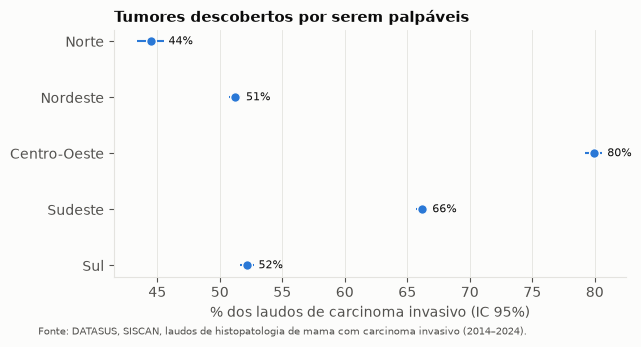

,regiao_res,n,eventos,pct,ic_inf,ic_sup
0,Centro-Oeste,12395,9907,79.9,79.2,80.6
1,Nordeste,43356,22202,51.2,50.7,51.7
2,Norte,8598,3824,44.5,43.4,45.5
3,Sudeste,39119,25887,66.2,65.7,66.6
4,Sul,30016,15663,52.2,51.6,52.7


In [6]:
print(hp.groupby("ano").size().rename("laudos de carcinoma invasivo").to_frame().T)
palp = ras.palpavel(hp, ["regiao_res"])
base.salvar_tabela(palp, "03_lesao_palpavel_regiao")
fig, ax = g.pontos_ic(palp.assign(todas="todas"), "regiao_res", "todas",
                      "Tumores descobertos por serem palpáveis", "% dos laudos de carcinoma invasivo (IC 95%)",
                      ordem_cat=c.REGIOES, figsize=(6.6, 3.2))
g.salvar(fig, "03_lesao_palpavel", FONTE_HISTO)
plt.show()
palp

No país, 58% dos cânceres de mama biopsiados no SUS já eram palpáveis, ou seja, foram descobertos porque a mulher ou o profissional sentiu o nódulo, e não pela mamografia. Esse é um sinal de que, para a maioria das mulheres atendidas no SUS, o rastreamento ainda não está antecipando o diagnóstico.

A comparação entre regiões, porém, não deve ser usada. Os valores não seguem o padrão dos outros indicadores (o Centro-Oeste aparece com 80% e o Norte com 45%), o que sugere que o campo é preenchido de formas diferentes em cada lugar. O número de laudos registrados também cresceu muito ao longo dos anos, de 4 mil em 2014 para 25 mil em 2024, mostrando que o uso do SISCAN ainda está se expandindo.

## O que levar para o TCC

O SUS registrou 3,6 milhões de mamografias em 2024, quase todas de rastreamento, e dois terços delas na faixa recomendada de 50 a 69 anos. Medido contra a meta de examinar metade das mulheres dessa idade a cada ano, o rastreamento registrado alcança entre 14% e 25% da meta, com o Norte no ponto mais baixo; esses valores subestimam o real, por sub-registro, mas a comparação entre regiões é informativa. O Norte também tem a maior espera pelo laudo da mamografia. E 58% dos tumores biopsiados no SUS já eram palpáveis, o que indica que a maioria dos cânceres ainda é encontrada pelo toque, e não pelo rastreamento. Ao usar o SISCAN no texto, é preciso mencionar o sub-registro.